# Why measure a test: size, power and the Monte Carlo error

**Question:** When the binomial test is run on a portfolio whose PD is exactly right, how often does it still reject at the 5% level, and how many repetitions does a measurement need before that rate can be trusted?

- **Level:** 1, Fundamentals
- **Prerequisites:** topic 01 (the notebooks that open a committed artifact and read a `TestResult`)
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- say what the size and the power of a validation test are, and why a test that was never run on data of known truth has unknown error rates;
- read one row of the Contraste study as a simulation experiment: a generator whose truth is written down, a test, a seed and a number of repetitions;
- find the critical default count of a test and the exact probability that it rejects, without drawing a single dataset;
- turn a rejection rate into an estimate with a Monte Carlo error and a Wilson interval, and say how both shrink with the number of repetitions;
- judge a rate against the size bound of the study when no exact value exists.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The data is case C22 of Contraste, validating the validator, and nothing in it is portfolio data of a bank. Each dataset is drawn by a known-truth generator of `riskvalidation.generators` (licence MIT, class `generated`), so the truth behind every number is written next to it. This notebook reads the `null` family: every test with a p-value, run on data where its null hypothesis holds and its assumptions are met, so a correct test should reject about 5% of the time at the 5% level.

- **File read:** `data/derived/C22/null.json`, the keys `outputs` (the simulations, the configuration of each generator and the size bounds) and `provenance`.
- **What is taken from it:** the configuration, the seed and the number of repetitions of each row. The engine draws the datasets again, here, from that configuration.

The next cell loads the file, indexes the rows by key and prints the engine version that wrote the file beside the one installed.

In [2]:
# Load the null family of case C22 and index its simulations by key
LANG = "en"
ROOT = Path("../../..").resolve()
null = json.loads((ROOT / "data" / "derived" / "C22" / "null.json").read_text(encoding="utf-8"))
out = null["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
print("simulations in the file:", len(rows))
print("baked by riskvalidation", null["provenance"]["riskvalidation_version"], "|", "installed", rv.__version__)

simulations in the file: 53
baked by riskvalidation 1.0.1 | installed 1.0.1


## Method

A simulation study is an experiment, and Morris, White and Crowther (2019) give its report five parts: aims, data-generating mechanisms, estimands, methods and performance measures. In Contraste's rows the aim is the question "does this test hold its size?", the mechanism is a generator with a stated truth, the estimand is the probability that the test rejects at level $\alpha$, the method is a registered test with the rule `p<0.05` or `p<0.01`, and the performance measure is the rejection rate with its error.

The size of a test is its rejection probability when the null hypothesis is true. The power is its rejection probability when a defect of known severity is planted. Both are probabilities, so a simulation can only estimate them, and a count test can also have them computed exactly. The steps below build one row from its configuration, compute its exact size, estimate the same size by simulation, compare the two, and watch the estimate settle as repetitions grow.

### Step 1: one row, read as an experiment

The row `pd.binomial@null` is the binomial test on a portfolio of 1,000 obligors whose PD of 1% is exactly right. The generator class is `DefaultCounts`; the configuration in the file is enough to build it, and its `truth()` method states what the data is. The next cell builds it and prints the truth, the test, the repetitions and the seed.

In [3]:
# Rebuild the generator from the committed configuration and read its truth
from riskvalidation.generators.counts import DefaultCounts, feed_cell

row = rows["pd.binomial@null"]
spec = out["generators"][row["generator"]]
generator = DefaultCounts(**spec["config"])
truth = generator.truth()
print("obligors:", truth["obligors"][0][0], "| PD:", truth["pd_true"][0][0])
print("PD applied:", truth["pd_forecast"][0][0])
print("expected defaults:", truth["expected_defaults"][0][0])
print("variance of the count:", truth["variance_defaults"][0][0])
print("null holds at the boundary:", truth["calibration_null_holds"])
print("test:", row["test_id"], "| repetitions:", row["n_rep"], "| seed:", row["seed"])

obligors: 1000 | PD: 0.01
PD applied: 0.01
expected defaults: 10.0
variance of the count: 9.9
null holds at the boundary: True
test: pd.binomial | repetitions: 4000 | seed: 3913381310


The truth says that each draw has 1,000 obligors with a true PD of 1% and the same PD applied, so 10 defaults are expected and, with independent obligors, the count has a variance of 9.9. Because the PD applied equals the true PD, the null hypothesis holds at its boundary and every rejection the test produces is a false alarm. That is what makes the row a measurement of size, and the seed with the 4000 repetitions makes it repeatable.

### Step 2: the exact size, without simulating

A count test sees the portfolio only through the number of defaults $D$. The engine finds the smallest count $k^*$ whose p-value falls below $\alpha$ by calling the registered test itself, and the test rejects exactly when $D \ge k^*$. Because $D$ is discrete, the true size is the tail probability

$$P(\text{reject}) = P(D \ge k^*), \qquad D \sim \mathrm{Binomial}(n, \pi),$$

which is rarely equal to $\alpha$. The next cell asks for the probability of every count with `count_pmf`, the critical count with `critical_count` and the exact size with `rejection_probability`, and draws the distribution with the rejection region in red.

critical count at 5%: 16 | exact size: 0.04787


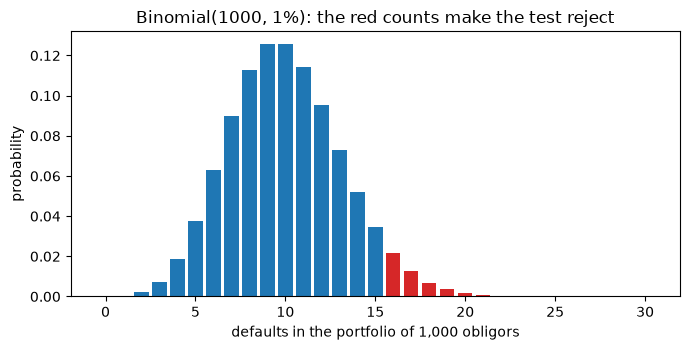

In [4]:
# Probability of each default count, critical count and exact size of the test
from riskvalidation.harness.exact import count_pmf, critical_count, rejection_probability

pmf = count_pmf(1000, 0.01)
k_star = critical_count("pd.binomial", 1000, 0.01, 0.05)
size = rejection_probability("pd.binomial", 1000, 0.01, 0.05)["probability"]
print("critical count at 5%:", k_star, "| exact size:", round(size, 5))
ks = np.arange(0, 31)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(ks, pmf[:31], color=np.where(ks >= k_star, "tab:red", "tab:blue"))
ax.set_xlabel("defaults in the portfolio of 1,000 obligors")
ax.set_ylabel("probability")
ax.set_title("Binomial(1000, 1%): the red counts make the test reject")
fig.tight_layout()
plt.show()

The red bars start at 16 defaults: with 10 expected, the test needs six more than expected before it calls the PD wrong. The red area adds up to 0.04787, so the test rejects a right model 4.79% of the time, not 5%. The gap is the price of a discrete count, where no integer threshold has a tail of exactly 5%. This exact value is the reference against which the simulated rate of the next steps will be read.

### Step 3: the simulated rate is an estimate

With $n$ repetitions and $k$ rejections the rate $\hat r = k/n$ estimates the rejection probability. Its Monte Carlo standard error is $\sqrt{\hat r(1-\hat r)/n}$ (Morris, White and Crowther, 2019, Table 6), and the Wilson interval, recommended by Brown, Cai and DasGupta (2001) for a binomial proportion, behaves well near zero where small sizes live. The engine's `simulate` draws the datasets, runs the test on each and returns `Rate` objects that hold the counts. The next cell runs the row with its committed seed and prints the rate, its error and its interval.

In [5]:
# Replay the row with its seed and read the rate, its error and its Wilson interval
from riskvalidation.harness.run import simulate

sim = simulate(row["test_id"], generator, n_rep=row["n_rep"], seed=row["seed"], feed=feed_cell())
rate = sim.rates["p<0.05"]
low, high = rate.interval
print("rejections:", rate.rejections, "of", rate.n)
print("rate at 5%:", rate.rate, "| Monte Carlo error:", round(rate.se, 5))
print("Wilson interval:", round(low, 5), "to", round(high, 5))
print("error from the formula:", round(float(np.sqrt(rate.rate * (1 - rate.rate) / rate.n)), 5))

rejections: 182 of 4000
rate at 5%: 0.0455 | Monte Carlo error: 0.0033
Wilson interval: 0.03947 to 0.05241
error from the formula: 0.0033


The test rejected 182 of the 4000 repetitions, a rate of 0.0455. The error of 0.0033 equals the formula, and the Wilson interval runs from 0.03947 to 0.05241. The exact size of 0.04787 sits inside that interval, so the simulation and the computation tell one story. A rate quoted without its error or interval cannot be read, because the same 182 rejections could come from a size anywhere between about 3.9% and 5.2%.

### Step 4: does the simulation agree with the exact value?

When an exact probability $p$ exists, the engine's `agrees` accepts a simulated rate if

$$|\hat r - p| \le z\,\sqrt{p(1-p)/n}, \qquad z = 3.29,$$

the two-sided 0.1% point. The wide $z$ is deliberate, because the study makes dozens of such comparisons and a tight one would flag noise. The next cell simulates the binomial and the Jeffreys tests at 5% and 1%, computes the exact size of each, prints the standardised gap $z$ and the verdict of `agrees`, and draws each rate with its interval beside the exact value.

pd.binomial  0.05 | simulated 0.04550 | exact 0.04787 | z -0.70 | True
pd.binomial  0.01 | simulated 0.00600 | exact 0.00690 | z -0.69 | True
pd.jeffreys  0.05 | simulated 0.03900 | exact 0.04787 | z -2.63 | True
pd.jeffreys  0.01 | simulated 0.01125 | exact 0.01383 | z -1.40 | True


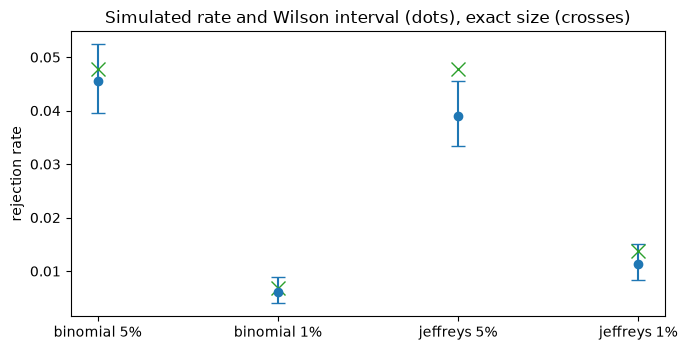

In [6]:
# Simulate two count tests at two levels and set each rate against its exact size
from riskvalidation.harness.rates import agrees

points = []
for test in ("pd.binomial", "pd.jeffreys"):
    run = simulate(test, generator, n_rep=4000, seed=rows[f"{test}@null"]["seed"], feed=feed_cell())
    for alpha in (0.05, 0.01):
        measured = run.rates[f"p<{alpha}"]
        exact = rejection_probability(test, 1000, 0.01, alpha)["probability"]
        gap = (measured.rate - exact) / np.sqrt(exact * (1 - exact) / measured.n)
        points.append((f"{test[3:]} {alpha:.0%}", measured, exact))
        verdict = agrees(measured, exact)
        print(f"{test:12s} {alpha:.2f} | simulated {measured.rate:.5f} | exact {exact:.5f} | z {gap:+.2f} | {verdict}")
fig, ax = plt.subplots(figsize=(7, 3.6))
for position, (label, measured, exact) in enumerate(points):
    low, high = measured.interval
    errors = [[measured.rate - low], [high - measured.rate]]
    ax.errorbar(position, measured.rate, yerr=errors, fmt="o", capsize=5, color="tab:blue")
    ax.plot(position, exact, "x", color="tab:green", markersize=10)
ax.set_xticks(range(len(points)))
ax.set_xticklabels([p[0] for p in points])
ax.set_ylabel("rejection rate")
ax.set_title("Simulated rate and Wilson interval (dots), exact size (crosses)")
fig.tight_layout()
plt.show()

All four simulated rates agree with their exact values, and the largest standardised gap is -2.63, for the Jeffreys test at 5%, inside the limit of 3.29. The Jeffreys test is also the one to watch: its exact size at the 1% level is 0.01383, above the nominal 1%, while the binomial test is below it at 0.00690. A simulation that matches an exact value is evidence that the generator, the harness and the test are wired as intended, which is why the study checks every row that has one.

### Step 5: a size bound for the tests with no exact value

Most tests have no exact rejection probability. For them the question is one-sided: is the rate compatible with a true size of at most $\alpha$? The engine answers with the bound $\alpha + z\sqrt{\alpha(1-\alpha)/n}$ at $z = 3.09$, the one-sided 0.1% point, and `within_size` compares a rate with it. The next cell prints the bound for 4000 repetitions and applies `within_size` to four rows: the binomial and Jeffreys tests, the population stability index (PSI) test on two samples of 1,000, and the normal test over five years. Each generator is rebuilt from the file and each row is run with its own seed.

In [7]:
# Apply the size bound of 4000 repetitions to the rate of four tests
from riskvalidation.generators.counts import feed_series
from riskvalidation.generators.drift import TwoSample
from riskvalidation.harness.rates import size_bound, within_size

CLASSES = {cls.name: cls for cls in (DefaultCounts, TwoSample)}
print("bound at 5%:", round(size_bound(0.05, 4000), 5), "| bound at 1%:", round(size_bound(0.01, 4000), 5))
for key in ("pd.binomial@null", "stability.psi@null", "pd.normal_multiperiod@null", "pd.jeffreys@null"):
    item = rows[key]
    cfg = out["generators"][item["generator"]]
    gen = CLASSES[cfg["name"]](**cfg["config"])
    years = len(cfg["config"].get("obligors", [[0]]))
    feed = feed_series() if years > 1 else (feed_cell() if cfg["name"] == "default_counts" else None)
    run = simulate(item["test_id"], gen, n_rep=item["n_rep"], seed=item["seed"], feed=feed)
    measured = run.rates["p<0.05"]
    print(f"{item['test_id']:24s} rate at 5% {measured.rate:.5f} | within the bound {within_size(measured, 0.05)}")

bound at 5%: 0.06065 | bound at 1%: 0.01486
pd.binomial              rate at 5% 0.04550 | within the bound True
stability.psi            rate at 5% 0.05250 | within the bound True
pd.normal_multiperiod    rate at 5% 0.08375 | within the bound False
pd.jeffreys              rate at 5% 0.03900 | within the bound True


With 4000 repetitions, a rate above 0.06065 at the 5% level is not Monte Carlo noise. The binomial, Jeffreys and PSI tests sit inside it, with 0.04550, 0.03900 and 0.05250. The normal test over five years reaches 0.08375 and falls outside: it rejects a right model almost twice as often as it promises. This is the first sign that not every test holds its size, a question the next notebook of the topic answers for all twenty-one tests.

### Step 6: the Monte Carlo error shrinks with the repetitions

Repetition $i$ always draws from its own stream of the seed, so a run of 100 repetitions is the first 100 of a run of 4000. That makes a clean experiment: the same study stopped at four lengths. The standard error falls as $1/\sqrt{n}$, so a run four times longer has an interval half as wide. The next cell runs the binomial row at 100, 400, 1,600 and 4,000 repetitions and draws each rate with its Wilson interval beside the exact size and the nominal 5%.

n_rep   100 | rate 0.0600 | error 0.0237 | interval width 0.0970
n_rep   400 | rate 0.0425 | error 0.0101 | interval width 0.0403
n_rep  1600 | rate 0.0500 | error 0.0054 | interval width 0.0214
n_rep  4000 | rate 0.0455 | error 0.0033 | interval width 0.0129


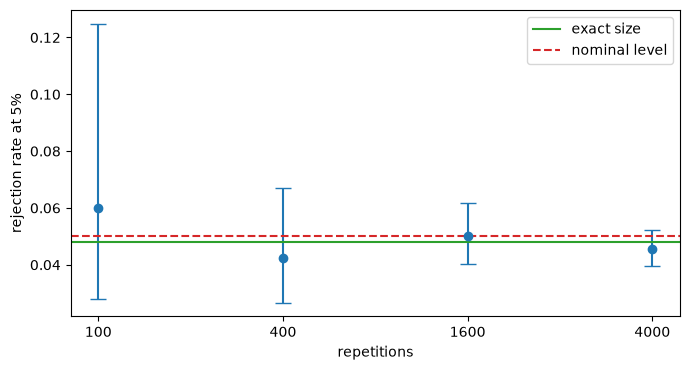

In [8]:
# Stop the same study at four lengths and draw each rate with its interval
lengths = (100, 400, 1600, 4000)
fig, ax = plt.subplots(figsize=(7, 3.8))
for position, n_rep in enumerate(lengths):
    run = simulate("pd.binomial", generator, n_rep=n_rep, seed=row["seed"], feed=feed_cell())
    r = run.rates["p<0.05"]
    low, high = r.interval
    print(f"n_rep {n_rep:5d} | rate {r.rate:.4f} | error {r.se:.4f} | interval width {high - low:.4f}")
    ax.errorbar(position, r.rate, yerr=[[r.rate - low], [high - r.rate]], fmt="o", capsize=6, color="tab:blue")
ax.axhline(size, color="tab:green", label="exact size")
ax.axhline(0.05, color="tab:red", linestyle="--", label="nominal level")
ax.set_xticks(range(len(lengths)))
ax.set_xticklabels([str(n) for n in lengths])
ax.set_xlabel("repetitions")
ax.set_ylabel("rejection rate at 5%")
ax.legend()
fig.tight_layout()
plt.show()

The interval is 0.0970 wide at 100 repetitions, 0.0403 at 400, 0.0214 at 1600 and 0.0129 at 4000, so each fourfold step roughly halves it. At 100 repetitions the rate of 0.0600 cannot tell a size of 4.8% from one of 6%, since the interval covers both and the nominal 5% as well. Only the longest run narrows the interval to about a point, which is why the study uses 4000 repetitions for the sizes and reports the interval beside every rate.

## Results

**Answer:** The binomial test rejects a right model 0.0455 of the time in the simulation, 182 rejections in 4000 repetitions, against an exact size of 0.04787 computed from its critical count of 16 defaults; the Monte Carlo error of 0.0033 and the Wilson interval from 0.03947 to 0.05241 show the two agree. A measurement of that kind needs thousands of repetitions: the interval is 0.0970 wide at 100 repetitions and 0.0129 at 4000, so the longer run is the only one that separates 0.0455 from the nominal 0.05 with some precision.

- **The nominal level is not the size.** The binomial test is built for 5% but rejects from 16 defaults, a tail of 0.04787, because the count is discrete. At the 1% level the exact sizes are 0.00690 for the binomial test and 0.01383 for the Jeffreys test, which sits above its nominal level for this portfolio with no simulation involved.
- **Simulation and exact value agree.** The largest standardised gap among the four comparisons is -2.63, inside the 3.29 criterion of `agrees`.
- **A bound for the rest.** At 4000 repetitions a size above 0.06065 is not noise. The PSI test sits inside the bound with 0.05250 and the normal test over five years sits outside it with 0.08375.

This notebook does not show the power of any test, the size of the other twenty tests or what correlated defaults do to the binomial test; the following notebooks of the topic take those up.

## Summary

- The size of a test is its rejection rate when its null holds, and its power is the rate against a planted defect of known severity; both are probabilities that a simulation estimates.
- A row of the study carries its five parts: aim, generator with a written truth, estimand, registered test and performance measures.
- For a count test the engine computes the critical count and the exact size, which the simulated rate must match within its Monte Carlo error.
- A rate is read with its error and Wilson interval, and both fall with the square root of the repetitions.
- Without an exact value, the size bound of the study tells noise from a size above the level.

**What to try next.** Run the same steps for `pd.jeffreys` at a PD of 0.5% and watch the critical count change, then read notebook 02, which measures all twenty-one tests.

## References

- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, section 2.5.3.1 (the Jeffreys test). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- This repository: `docs/design/features/c22-validator/requirements.md` (the requirements the C22 measurements hold) and `data-pipeline/pipeline/cases/c22_validator.py` (the bake that wrote the artifact).